# COFFEE SHOP REVENUE

### This project purpose is to get coffee shops daily activites to determine their daily revenue either it will be low or high,The aim is to help shops identify the activites that increase their revenue.

In [2]:
!pip install mlxtend

In [3]:
#Call libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import  r2_score,mean_squared_error,mean_absolute_error,accuracy_score
from mlxtend.feature_selection import ExhaustiveFeatureSelector

In [4]:
#Read data from file and display
Data=pd.read_csv('csr.csv')
Data.head()

,Number_of_Customers_Per_Day,Average_Order_Value,Operating_Hours_Per_Day,Number_of_Employees,Marketing_Spend_Per_Day,Location_Foot_Traffic,Daily_Revenue
0,152,6.74,14,4,106.62,97,1547.81
1,485,4.50,12,8,57.83,744,2084.68
2,398,9.09,6,6,91.76,636,3118.39
3,320,8.48,17,4,462.63,770,2912.20
4,156,7.44,17,2,412.52,232,1663.42


In [5]:
#Show information about each column
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Number_of_Customers_Per_Day  2000 non-null   int64  
 1   Average_Order_Value          2000 non-null   float64
 2   Operating_Hours_Per_Day      2000 non-null   int64  
 3   Number_of_Employees          2000 non-null   int64  
 4   Marketing_Spend_Per_Day      2000 non-null   float64
 5   Location_Foot_Traffic        2000 non-null   int64  
 6   Daily_Revenue                2000 non-null   float64
dtypes: float64(3), int64(4)
memory usage: 109.5 KB


In [6]:
#Check for null values
null_values = Data.isnull().sum()
print("Null Values in Each Column:")
null_values

Null Values in Each Column:


Number_of_Customers_Per_Day    0
Average_Order_Value            0
Operating_Hours_Per_Day        0
Number_of_Employees            0
Marketing_Spend_Per_Day        0
Location_Foot_Traffic          0
Daily_Revenue                  0
dtype: int64

In [7]:
#Statistical Summary of set
Data.describe()

,Number_of_Customers_Per_Day,Average_Order_Value,Operating_Hours_Per_Day,Number_of_Employees,Marketing_Spend_Per_Day,Location_Foot_Traffic,Daily_Revenue
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,274.296000,6.261215,11.667000,7.947000,252.614160,534.893500,1917.325940
std,129.441933,2.175832,3.438608,3.742218,141.136004,271.662295,976.202746
min,50.000000,2.500000,6.000000,2.000000,10.120000,50.000000,-58.950000
25%,164.000000,4.410000,9.000000,5.000000,130.125000,302.000000,1140.085000
50%,275.000000,6.300000,12.000000,8.000000,250.995000,540.000000,1770.775000
75%,386.000000,8.120000,15.000000,11.000000,375.352500,767.000000,2530.455000
max,499.000000,10.000000,17.000000,14.000000,499.740000,999.000000,5114.600000


## Data Cleaning
### There is no missing data,noisy or corrupted data,below code just to show how missing data will be  handled if exists.

#### Fill Null Values with their median beacuase it does not get affected by outliers 

In [8]:
Data = Data.fillna(Data.median())
Data.head()

,Number_of_Customers_Per_Day,Average_Order_Value,Operating_Hours_Per_Day,Number_of_Employees,Marketing_Spend_Per_Day,Location_Foot_Traffic,Daily_Revenue
0,152,6.74,14,4,106.62,97,1547.81
1,485,4.50,12,8,57.83,744,2084.68
2,398,9.09,6,6,91.76,636,3118.39
3,320,8.48,17,4,462.63,770,2912.20
4,156,7.44,17,2,412.52,232,1663.42


## Exploratory Data Analysis

In [9]:
#Getting lower and upper limits to remove outliers
def out(c):
    Q1=Data[c].quantile(0.25) 
    Q3=Data[c].quantile(0.75) 
    IQR=Q3-Q1 
    low=Q1-(1.5*IQR) 
    upp=Q3+(1.5*IQR) 
    return low,upp 
l,u=out('Daily_Revenue')
print('IQR Values: ',l,',',u)

IQR Values:  -945.4699999999998 , 4616.01


In [10]:
#Display outliers
Data[~Data['Daily_Revenue'].between(l,u)]

,Number_of_Customers_Per_Day,Average_Order_Value,Operating_Hours_Per_Day,Number_of_Employees,Marketing_Spend_Per_Day,Location_Foot_Traffic,Daily_Revenue
66,416,9.98,17,10,483.07,576,4737.16
85,451,9.88,15,14,493.23,879,4750.98
701,494,9.57,13,8,385.76,686,4646.33
1143,473,9.79,9,14,479.41,303,4756.55
1171,495,9.95,17,4,11.79,417,4634.73
1318,484,9.10,17,6,467.00,657,4626.59
1593,453,9.93,12,7,474.97,563,5114.60
1719,495,9.63,12,3,356.89,139,4881.00
1842,465,9.75,10,14,412.11,384,4667.03


In [11]:
#Replace outliers with the column median for better analysis
Data.loc[~Data['Daily_Revenue'].between(l,u),'Daily_Revenue']=Data['Daily_Revenue'].median()
Data.head()

,Number_of_Customers_Per_Day,Average_Order_Value,Operating_Hours_Per_Day,Number_of_Employees,Marketing_Spend_Per_Day,Location_Foot_Traffic,Daily_Revenue
0,152,6.74,14,4,106.62,97,1547.81
1,485,4.50,12,8,57.83,744,2084.68
2,398,9.09,6,6,91.76,636,3118.39
3,320,8.48,17,4,462.63,770,2912.20
4,156,7.44,17,2,412.52,232,1663.42


In [12]:
#After removing outliers
Data[~Data['Daily_Revenue'].between(l,u)]

,Number_of_Customers_Per_Day,Average_Order_Value,Operating_Hours_Per_Day,Number_of_Employees,Marketing_Spend_Per_Day,Location_Foot_Traffic,Daily_Revenue


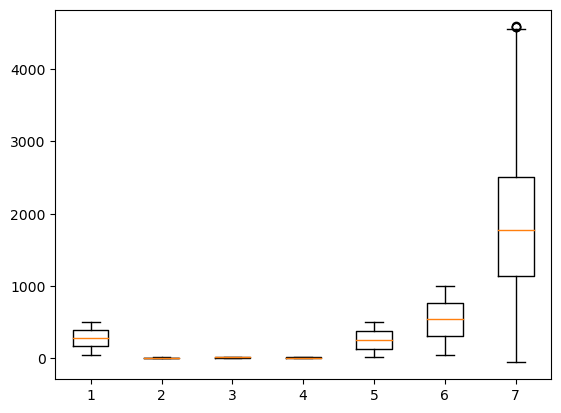

In [13]:
#Boxplot to show After removing outliers
plt.boxplot(Data)
plt.show()

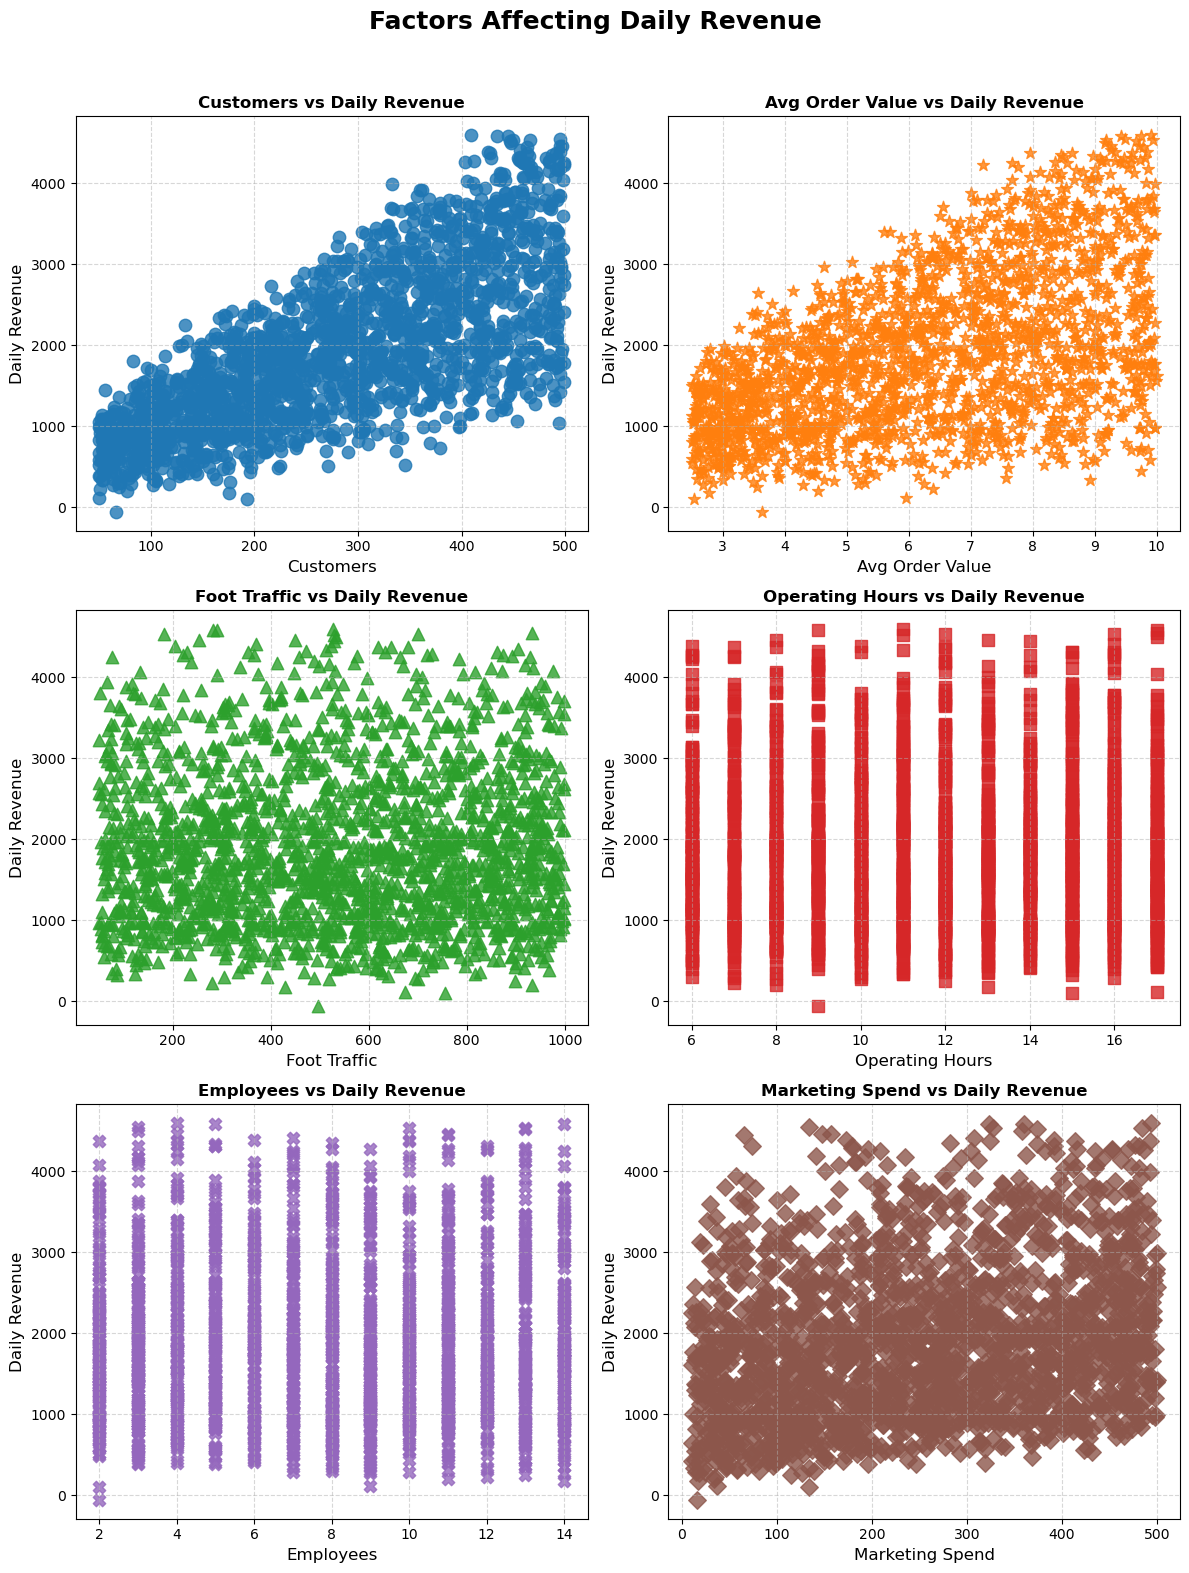

In [14]:
# plot to show how each factor affects daily revenue of coffee shops
plt.figure(figsize=(12,16))
plt.suptitle("Factors Affecting Daily Revenue", fontsize=18, fontweight='bold')

plots = [
    ('Number_of_Customers_Per_Day', 'Customers', 'o', '#1f77b4'),
    ('Average_Order_Value', 'Avg Order Value', '*', '#ff7f0e'),
    ('Location_Foot_Traffic', 'Foot Traffic', '^', '#2ca02c'),
    ('Operating_Hours_Per_Day', 'Operating Hours', 's', '#d62728'),
    ('Number_of_Employees', 'Employees', 'X', '#9467bd'),
    ('Marketing_Spend_Per_Day', 'Marketing Spend', 'D', '#8c564b')
]

for i, (col, xlabel, marker, color) in enumerate(plots, 1):
    plt.subplot(3, 2, i)
    plt.scatter(Data[col], Data['Daily_Revenue'], marker=marker, color=color, s=80, alpha=0.8)
    plt.xlabel(xlabel, fontsize=12)
    plt.ylabel('Daily Revenue', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.title(f'{xlabel} vs Daily Revenue', fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [15]:
#Display correlation between variables
Data.corr()

,Number_of_Customers_Per_Day,Average_Order_Value,Operating_Hours_Per_Day,Number_of_Employees,Marketing_Spend_Per_Day,Location_Foot_Traffic,Daily_Revenue
Number_of_Customers_Per_Day,1.000000,-0.014647,0.000122,0.000346,0.027184,-0.000880,0.729829
Average_Order_Value,-0.014647,1.000000,-0.017125,0.011484,0.018782,0.018151,0.523827
Operating_Hours_Per_Day,0.000122,-0.017125,1.000000,-0.030451,0.019247,0.014422,-0.012942
Number_of_Employees,0.000346,0.011484,-0.030451,1.000000,0.026535,-0.041881,-0.000057
Marketing_Spend_Per_Day,0.027184,0.018782,0.019247,0.026535,1.000000,-0.012562,0.245348
Location_Foot_Traffic,-0.000880,0.018151,0.014422,-0.041881,-0.012562,1.000000,0.015030
Daily_Revenue,0.729829,0.523827,-0.012942,-0.000057,0.245348,0.015030,1.000000


<Axes: >

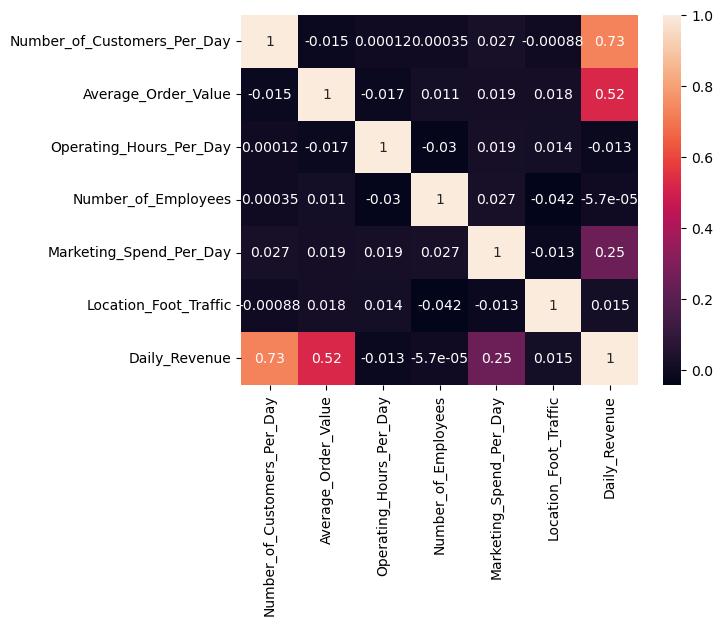

In [16]:
#Visual representation of correlation between variables
#It shows that the most contribution to daily revenue are no.of.customers and Avg_order_value
sn.heatmap(Data.corr(),annot=True)

In [17]:
# Sperating features X and target y
x = Data.iloc[:,:-1]
x

,Number_of_Customers_Per_Day,Average_Order_Value,Operating_Hours_Per_Day,Number_of_Employees,Marketing_Spend_Per_Day,Location_Foot_Traffic
0,152,6.74,14,4,106.62,97
1,485,4.50,12,8,57.83,744
2,398,9.09,6,6,91.76,636
3,320,8.48,17,4,462.63,770
4,156,7.44,17,2,412.52,232
...,...,...,...,...,...,...
1995,372,6.41,11,4,466.11,913
1996,105,3.01,11,7,12.62,235
1997,89,5.28,16,9,376.64,310
1998,403,9.41,7,12,452.49,577


In [18]:
# Our target is (Daily_Revenue)
y = Data.iloc[:,-1]
y

0       1547.81
1       2084.68
2       3118.39
3       2912.20
4       1663.42
         ...   
1995    2816.85
1996     337.97
1997     951.34
1998    4266.21
1999     914.24
Name: Daily_Revenue, Length: 2000, dtype: float64

In [19]:
#Random Forest for Feature Importance or Selection 
#To know the strength of each factor affect on the revenue
RF = RandomForestRegressor()
RF.fit(x,y)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [20]:
#highest to lowest contributing features on target
R_DataFrame = pd.DataFrame({"Features":x.columns,"RF Score":RF.feature_importances_}).sort_values('RF Score',ascending=False)
R_DataFrame

,Features,RF Score
0,Number_of_Customers_Per_Day,0.569441
1,Average_Order_Value,0.348673
4,Marketing_Spend_Per_Day,0.057702
5,Location_Foot_Traffic,0.010001
3,Number_of_Employees,0.007270
2,Operating_Hours_Per_Day,0.006913


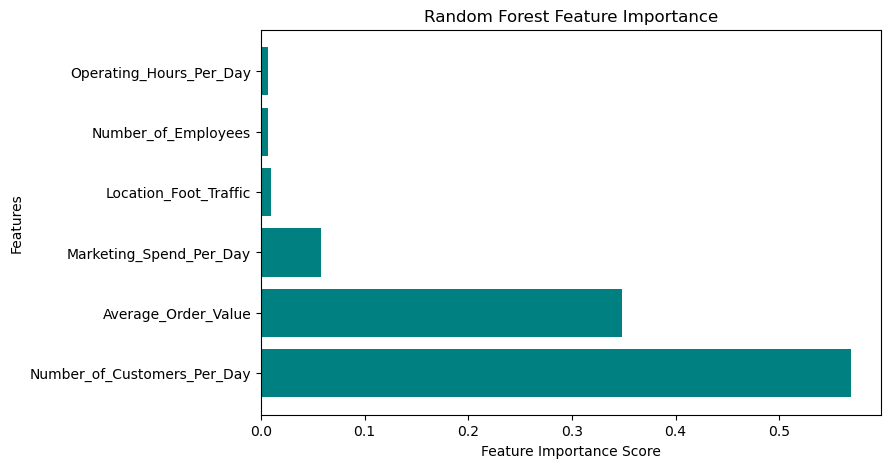

In [21]:
#To see which most contributing features
plt.figure(figsize=(8,5))
plt.barh(R_DataFrame['Features'], R_DataFrame['RF Score'], color='#008080')
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.show()

In [23]:
#Picking Best Features(Exhaustive feature selection (EFS))
LR = LinearRegression()
EFS = ExhaustiveFeatureSelector(estimator=LR,
                         max_features=2,
                         scoring="r2")
EFS.fit(x,y)

Features: 21/21

,estimator,LinearRegression()
,min_features,1
,max_features,2
,print_progress,True
,scoring,'r2'
,cv,5
,n_jobs,1
,pre_dispatch,'2*n_jobs'
,clone_estimator,True
,fixed_features,None
,feature_groups,"[[0], [1], ...]"


In [24]:
print('Best Contributing Features to the Target are')
list(EFS.best_feature_names_)

Best Contributing Features to the Target are


['Number_of_Customers_Per_Day', 'Average_Order_Value']

#### No feature was excluded, as all variables showed non-zero importance(Randim Forest) and contribute to revenue, even at a minimal level.

In [25]:
#Split data for training in regression model(to satisfy project requirments)
x_train_reg, x_test_reg, y_train_reg, y_test_reg = train_test_split(x, y, test_size=0.30, random_state=1)

In [26]:
LR.fit(x_train_reg, y_train_reg)
y_pred_reg = LR.predict(x_test_reg)

In [27]:
print("Regression Evaluation Metrics:")
print("R2 Score:", r2_score(y_test_reg,y_pred_reg))
print("MSE:", mean_squared_error(y_test_reg,y_pred_reg))
print("MAE:", mean_absolute_error(y_test_reg,y_pred_reg))

Regression Evaluation Metrics:
R2 Score: 0.861577603900841
MSE: 127674.66920631375
MAE: 261.55700943433595


#### According to R2 score model is accurate about 0.86 to predict revenue

In [28]:
#classification Beacuse our target is continuous
y = (y > y.median()).astype(int)

In [29]:
#Spliting Data into Training and Testing Sets, we choose 30% for testing and 70% for training
#in classification model(Needed for project objective)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=1)

In [30]:
#Training the dataset
logistic = LogisticRegression()
logistic.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [31]:
#Show model prediction of high or low revenue
y_pred_class = logistic.predict(x_test)
y_pred_class

array([1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0,
       1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1,

In [32]:
#accuracy of trained model
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_class))

Logistic Regression Accuracy: 0.9116666666666666


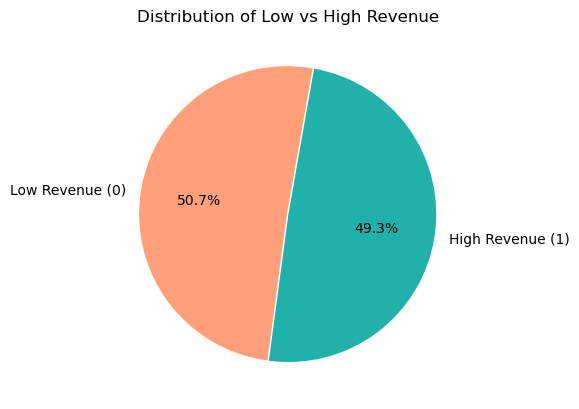

In [33]:
#Visualise the predicted output where low=0 and high=1
counts = y_test.value_counts()  
plt.pie(counts, labels=['Low Revenue (0)', 'High Revenue (1)'], 
        autopct='%1.1f%%', startangle=80, colors=['#FFA07A', '#20B2AA'],explode=[0.01,0])
plt.title("Distribution of Low vs High Revenue")
plt.show()

## Interpretaion of Results 
####  The model predicted that around 51% of days had low revenue. This shows that coffee shops could focus on strategies to increase the number of customers and the average order value, such as improving marketing campaigns, promotions,etc to increase their overall revenue.